In [1]:
# Regression

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

Weights : 2.80
Intercept : 4.14
R-Squared : 0.81


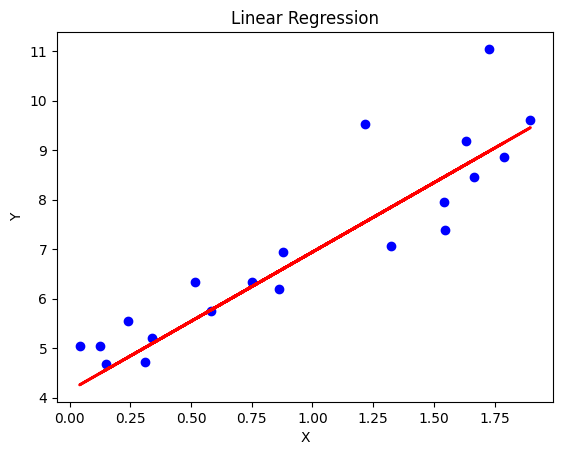

In [2]:
# Generate Sample Data
np.random.seed(42)
x = 2 * np.random.rand(100, 1)
y = 4 + 3 * x + np.random.randn(100, 1)

# Split Data
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

# Create And Train The Model
model = LinearRegression()
model.fit(x_train, y_train)

# Make Predictions
y_pred = model.predict(x_test)

# Print Results
print(f'Weights : {model.coef_[0][0]:.2f}')
print(f'Intercept : {model.intercept_[0]:.2f}')
print(f'R-Squared : {r2_score(y_test, y_pred):.2f}')

# Plot Results
plt.scatter(x_test, y_test, color='b')
plt.plot(x_test, y_pred, color='r', linewidth=2)
plt.title('Linear Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [3]:
# Multiple Linear Regression

# Generate Sample Data
np.random.seed(42)
x = 2 * np.random.rand(100, 3)
y = 4 + np.dot(x, np.array([2, 3, 4])) + np.random.randn(100)

# Split Data
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

# Create And Train The Model
model = LinearRegression()
model.fit(x_train, y_train)

# Make Predictions
y_pred = model.predict(x_test)

# Print Results
print(f'Weights : {model.coef_}')
print(f'Intercept : {model.intercept_:.2f}')
print(f'R-Squared : {r2_score(y_test, y_pred):.2f}')

Weights : [2.05294884 2.962303   4.34302962]
Intercept : 3.91
R-Squared : 0.85


Weights : [3.24999196 1.10536011]
Intercept : 3.81
R-Squared : 0.54


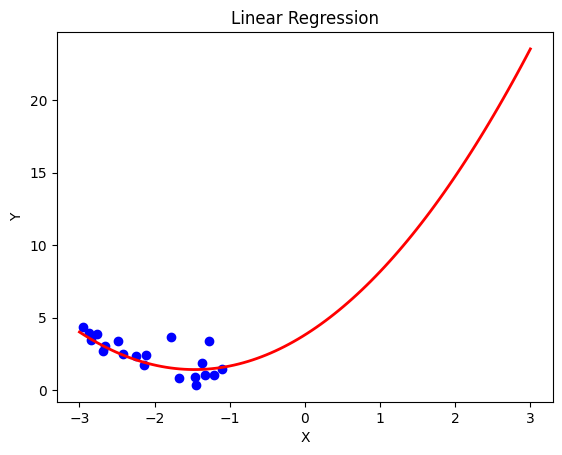

In [4]:
# Polynomial Regression

# Generate Sample Data
np.random.seed(42)
x = 2 * np.random.rand(100, 1) - 3
y = .5 * x**2 + x + 2 + np.random.randn(100, 1)

# Split Data
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

# Create Polynomial Features
poly_features = PolynomialFeatures(degree=2, include_bias=False)
x_poly_train = poly_features.fit_transform(x_train)
x_poly_test = poly_features.transform(x_test)

# Create And Train The Model
model = LinearRegression()
model.fit(x_poly_train, y_train)

# Make Predictions
y_pred = model.predict(x_poly_test)

# Print Results
print(f'Weights : {model.coef_[0]}')
print(f'Intercept : {model.intercept_[0]:.2f}')
print(f'R-Squared : {r2_score(y_test, y_pred):.2f}')

# Plot Results
x_plot = np.linspace(-3, 3, 100).reshape(-1, 1)
x_plot_poly = poly_features.transform(x_plot)
y_plot = model.predict(x_plot_poly)

plt.scatter(x_test, y_test, color='b')
plt.plot(x_plot, y_plot, color='r', linewidth=2)
plt.title('Linear Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [ ]:
# Regularization
# Lasso (L1)
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(x_train, y_train)

# Make Predictions
y_pred_lasso = lasso_model.predict(x_test)

# Print Results
print(f"Lasso Coefficients : {lasso_model.coef_}")
print(f"Lasso Intercept : {lasso_model.intercept_}")
print(f"Lasso R-Squared : {r2_score(y_test, y_pred):.2f}")


Lasso Coefficients : [-0.93006498]
Lasso Intercept : [0.2710422]
Lasso R-Squared : 0.54


In [ ]:
# Ridege Regression (L2)

# Create And Train Ridge Model
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(x_train, y_train)

# Make Predictions
y_pred_ridge = ridge_model.predict(x_test)

# Print Results
print(f"Lasso Coefficients : {ridge_model.coef_}")
print(f"Lasso Intercept : {ridge_model.intercept_}")
print(f"Lasso R-Squared : {r2_score(y_test, y_pred):.2f}")

Lasso Coefficients : [-1.22032107]
Lasso Intercept : [-0.32798917]
Lasso R-Squared : 0.54


In [8]:
# OLS Method
# Implement OLS Manually
x_with_intercept = np.c_[np.ones((x_train.shape[0], 1)), x_train]
beta_hat = np.linalg.inv(x_with_intercept.T.dot(x_with_intercept)).dot(x_with_intercept.T).dot(y_train)

print(f"OLS Coefficients (Including Intercept) : {beta_hat.flatten()}")

# Compare With Scikit-Learn's LinearRegression
sk_model = LinearRegression(fit_intercept=True)
sk_model.fit(x_train, y_train)

print(f"Scikit-Learn Coefficients : {sk_model.coef_.flatten()}")
print(f"Scikit-Learn Intercept : {sk_model.intercept_[0]:.2f}")



OLS Coefficients (Including Intercept) : [-0.33726834 -1.22481723]
Scikit-Learn Coefficients : [-1.22481723]
Scikit-Learn Intercept : -0.34


In [10]:
# Interpreting Regression Coefficients

from scipy import stats

# Function To Calculate P-Values For Coefficients
def calculate_pvalues(x, y, model):
    n = x.shape[0]
    p = x.shape[1]
    x_with_intercept = np.column_stack([np.ones(n), x])
    mse = np.sum((y - model.predict(x)) ** 2) / (n - p - 1)
    var_b = mse * np.linalg.inv(np.dot(x_with_intercept.T, x_with_intercept)).diagonal()
    sd_b = np.sqrt(var_b)
    t_stat = model.coef_ / sd_b[1:]
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_stat), n - p - 1))
    return p_values

# Generate Sample Data
np.random.seed(0)
x = np.random.rand(100, 3)
y = 2 + 3*x[:, 0] + 4*x[:, 2] + np.random.randn(100)

# Create And Train Model
model = LinearRegression()
model.fit(x,y)

# Calculate P-Values
p_values = calculate_pvalues(x, y, model)

# Print Results 
print("Coefficients : ")
for i, (coef, p_val) in enumerate(zip(model.coef_, p_values)):
    print(f"X{i+1} : {coef:.4f} (p-value: {p_val:.4f})")
    
print(f"Intercept : {model.intercept_:.4f}")

# Interpret The Results
print("Interpretation :")
for i, (coef, p_val) in enumerate(zip(model.coef_, p_values)):
    if(p_val<.05):
        print(f"X{i+1} Is Statistically Significant (p < 0.05) And Has a Coefficient Of {coef:.4f}")

    else:
        print(f"X{i+1} Is not Statistically Significant (p >= 0.05)")


Coefficients : 
X1 : 2.5913 (p-value: 0.0000)
X2 : -0.0200 (p-value: 0.9512)
X3 : 4.2532 (p-value: 0.0000)
Intercept : 1.9502
Interpretation :
X1 Is Statistically Significant (p < 0.05) And Has a Coefficient Of 2.5913
X2 Is not Statistically Significant (p >= 0.05)
X3 Is Statistically Significant (p < 0.05) And Has a Coefficient Of 4.2532


In [11]:
# Extending Linear Regression

# Generate Sample Data
np.random.seed(0)
x = np.random.rand(100, 2)
y = 1 + 2*x[:, 0] + 3*x[:, 1] + 4*x[:, 0]*x[:, 1] + np.random.randn(100)*.1

# Create Interaction Term
x_interact = np.column_stack([x, x[:, 0]* x[:, 1]])

# Split The Data
x_train, x_test, y_train, y_test = train_test_split(x_interact, y, test_size=0.2, random_state=42)

# Create And Train Model
model = LinearRegression()
model.fit(x_train, y_train)

# Make Predictions
y_pred = model.predict(x_test)

# Print Results
print("Coefficients: ")
print(f"X1 : {model.coef_[0]: .4f}")
print(f"X2 : {model.coef_[1]: .4f}")
print(f"X1*X2 (Interaction) : {model.coef_[2]: .4f}")
print(f"Intercept : {model.intercept_: .4f}")
print(f"R-Squared : {r2_score(y_test, y_pred): .4f}")

#Interpret The Results
print("Interpretation:")
print("The Effect Of X1 on y Depends On The Value Of X2, and vice versa")
print(f"When X2 is 0, a one-unit increase in x1 is associated with a {model.coef_[0]:.4f} increase in y")
print(f"When X1 is 0, a one-unit increase in x2 is associated with a {model.coef_[1]:.4f} increase in y")
print(f"The Interaction term {model.coef_[2]:.4f} represents how the effect of x1 changes for each one-unit increase in x2 (and vice versa)")

Coefficients: 
X1 :  1.9177
X2 :  2.9715
X1*X2 (Interaction) :  4.0758
Intercept :  1.0242
R-Squared :  0.9972
Interpretation:
The Effect Of X1 on y Depends On The Value Of X2, and vice versa
When X2 is 0, a one-unit increase in x1 is associated with a 1.9177 increase in y
When X1 is 0, a one-unit increase in x2 is associated with a 2.9715 increase in y
The Interaction term 4.0758 represents how the effect of x1 changes for each one-unit increase in x2 (and vice versa)


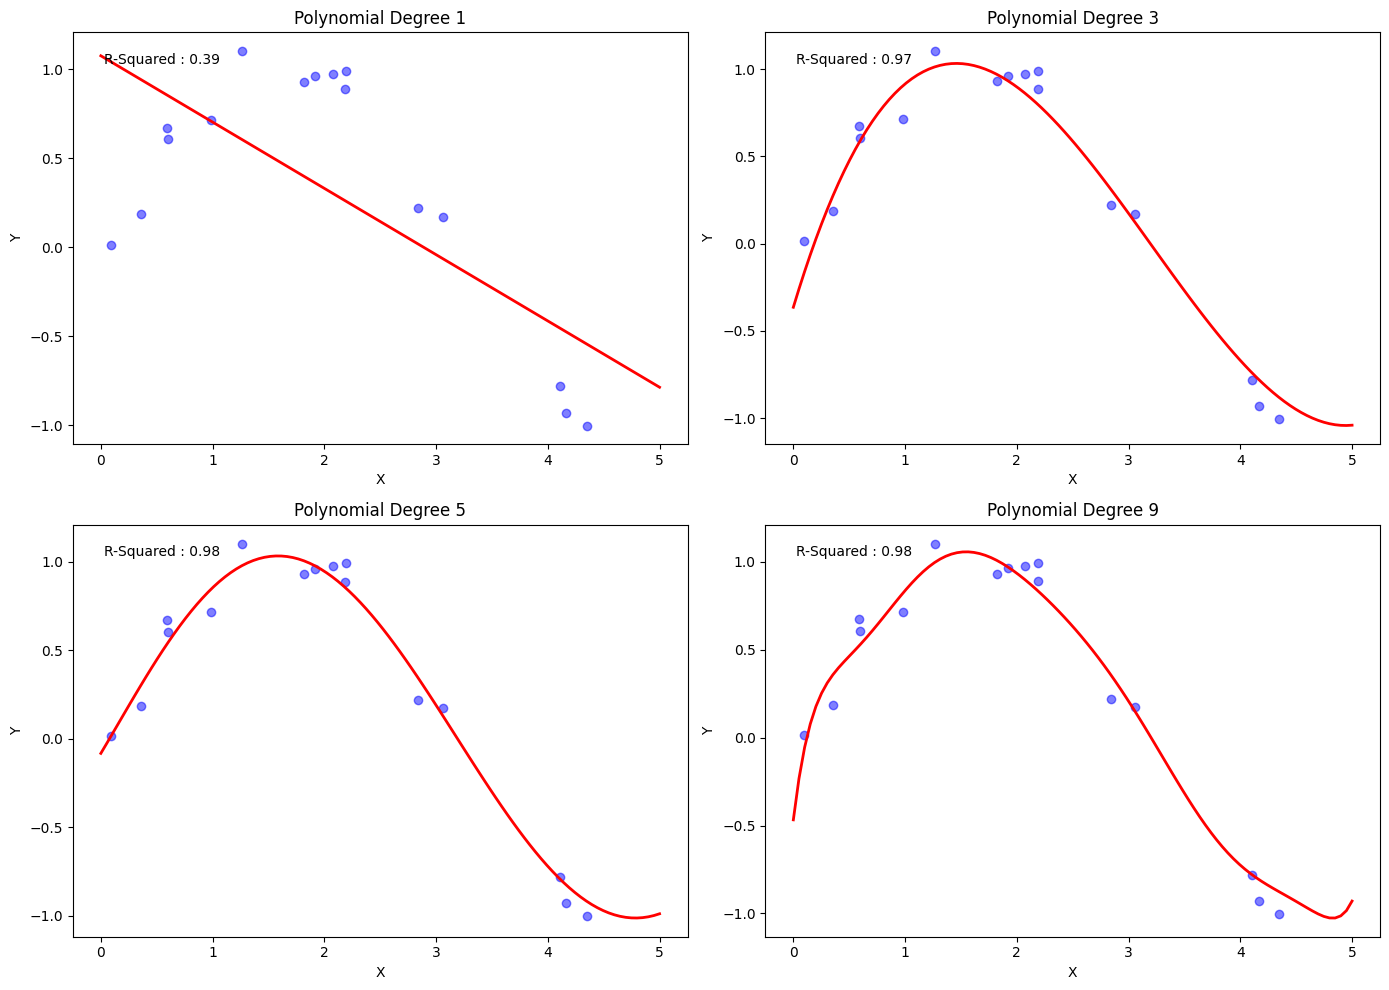

Interpretation:
As the degree of the polynomial increases, the model becomes more flexible and can capture more complex patterns.
However, high-degree polynomials may overfit the data, especially when there's limited training data.
The optimal degree depends on the true underlying relationship and the amount of noise in the data.


In [15]:
# Polynomial Regression And Flexibility

# Generate Sample Data
np.random.seed(0)
x = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(x).ravel() + np.random.normal(0, 0.1, x.shape[0])

# Split The Data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Create and Plot Models With Different Degrees
degrees = [1, 3, 5, 9]
plt.figure(figsize=(14, 10))

for i, degree in enumerate(degrees): 
    ax = plt.subplot(2, 2, i+1)
    
    poly_features = PolynomialFeatures(degree=degree, include_bias=False)
    x_poly_train = poly_features.fit_transform(x_train)
    x_poly_test = poly_features.transform(x_test)
    
    model = LinearRegression()
    model.fit(x_poly_train, y_train)
    
    y_pred = model.predict(x_poly_test)
    
    x_plot = np.linspace(0, 5, 100).reshape(-1, 1)
    x_plot_poly = poly_features.transform(x_plot)
    y_plot = model.predict(x_plot_poly)
    
    plt.scatter(x_test, y_test, color='b', alpha=0.5)
    plt.plot(x_plot, y_plot, color='r', linewidth=2)
    plt.title(f"Polynomial Degree {degree}")
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.text(0.05, 0.95, f'R-Squared : {r2_score(y_test, y_pred):.2f}' , transform=ax.transAxes, fontsize=10, verticalalignment='top')
    
    
plt.tight_layout()
plt.show()

print("Interpretation:")
print("As the degree of the polynomial increases, the model becomes more flexible and can capture more complex patterns.")
print("However, high-degree polynomials may overfit the data, especially when there's limited training data.")
print("The optimal degree depends on the true underlying relationship and the amount of noise in the data.")

In [18]:
# Generate sample data
np.random.seed(0)
X = np.sort(np.random.rand(100, 1), axis=0)
y = np.sin(2 * np.pi * X).ravel() + np.random.normal(0, 0.1, X.shape[0])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create polynomial features
poly_features = PolynomialFeatures(degree=5, include_bias=False)
X_poly_train = poly_features.fit_transform(X_train)
X_poly_test = poly_features.transform(X_test)

# Create and train models
models = {
'Linear' : LinearRegression(),
'Polynomial' : LinearRegression(),
'Ridge': Ridge(alpha=0.1),
'Lasso' : Lasso(alpha=0.1)
}

results = {}

for name, model in models.items():
    if name == 'Linear' :
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    else:
        model.fit(X_poly_train, y_train)
        y_pred = model.predict(X_poly_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MSE' : mse, 'R-squared' : r2}
    
# Print results
for name, metrics in results.items():
    print(f"{name} Regression:")
    print(f"  MSE: {metrics['MSE']:.4f}")
    print(f" R-squared: {metrics['R-squared']:.4f}")
    print ()
    
print("Interpretation:")
print("1. Linear regression may struggle with non-linear relationships, resulting in lower R-squared and higher MSE.")
print("2. Polynomial regression can capture non-linear patterns, potentially improving performance.")
print("3. Ridge and Lasso regression add regularization, which can help prevent overfitting in polynomial models.")
print("4. The best model depends on the true underlying relationship and the amount of noise in the data.")
print("5. Consider cross-validation and regularization parameter tuning for more robust model selection. ")

Linear Regression:
  MSE: 0.2630
 R-squared: 0.5756

Polynomial Regression:
  MSE: 0.0091
 R-squared: 0.9854

Ridge Regression:
  MSE: 0.1503
 R-squared: 0.7575

Lasso Regression:
  MSE: 0.4326
 R-squared: 0.3021

Interpretation:
1. Linear regression may struggle with non-linear relationships, resulting in lower R-squared and higher MSE.
2. Polynomial regression can capture non-linear patterns, potentially improving performance.
3. Ridge and Lasso regression add regularization, which can help prevent overfitting in polynomial models.
4. The best model depends on the true underlying relationship and the amount of noise in the data.
5. Consider cross-validation and regularization parameter tuning for more robust model selection. 
